In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from src.utils import *
import src.models as m
import optuna
from tqdm.autonotebook import tqdm
import itertools
import string
import seaborn as sns
from matplotlib.lines import Line2D

/opt/anaconda3/envs/movie_rec/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
FONTSIZE = 18
params = {
         'axes.labelsize': FONTSIZE,
         'axes.titlesize': FONTSIZE,
         'xtick.labelsize':FONTSIZE,
         'ytick.labelsize':FONTSIZE}
plt.rcParams.update(params)

In [3]:
path = './data'

folder = 'ml-32m' #'ml-latest-small'
experiment = 'experiments'
experiment_folder = os.path.join(experiment, folder)
image_folder = os.path.join(experiment_folder, "images")     # ./experiments/ml-32m/images
save_path = os.path.join(experiment_folder, 'model_files')
logs_path = os.path.join(experiment_folder, 'logs')

os.makedirs(image_folder, exist_ok=True)
os.makedirs(save_path, exist_ok=True)
os.makedirs(logs_path, exist_ok=True)

In [4]:
users_train = load_numpy_array(os.path.join(experiment, folder, 'data_split'), 'users_train')
users_test = load_numpy_array(os.path.join(experiment, folder, 'data_split'), 'users_test')
movies_train = load_numpy_array(os.path.join(experiment, folder, 'data_split'), 'movies_train')
movies_test = load_numpy_array(os.path.join(experiment, folder, 'data_split'), 'movies_test')
users_indices_train = load_numpy_array(os.path.join(experiment, folder, 'data_split'), 'users_indices_train')
users_indices_test = load_numpy_array(os.path.join(experiment, folder, 'data_split'), 'users_indices_test')
movies_indices_train = load_numpy_array(os.path.join(experiment, folder, 'data_split'), 'movies_indices_train')
movies_indices_test = load_numpy_array(os.path.join(experiment, folder, 'data_split'), 'movies_indices_test')
map_user_to_id = load_data_from_pickle(os.path.join(path, folder, 'preprocess'), 'map_user_to_id')
map_movie_to_id = load_data_from_pickle(os.path.join(path, folder, 'preprocess'),'map_movie_to_id')

Loaded users_train from .npy file at experiments/ml-32m/data_split
Loaded users_test from .npy file at experiments/ml-32m/data_split
Loaded movies_train from .npy file at experiments/ml-32m/data_split
Loaded movies_test from .npy file at experiments/ml-32m/data_split
Loaded users_indices_train from .npy file at experiments/ml-32m/data_split
Loaded users_indices_test from .npy file at experiments/ml-32m/data_split
Loaded movies_indices_train from .npy file at experiments/ml-32m/data_split
Loaded movies_indices_test from .npy file at experiments/ml-32m/data_split
Loaded map_user_to_id from .pkl file at ./data/ml-32m/preprocess
Loaded map_movie_to_id from .pkl file at ./data/ml-32m/preprocess


# Bias Only Model

In [5]:
def run_experiment(params, 
                   users_train, users_indices_train, 
                   movies_train, movies_indices_train,
                   users_test,  users_indices_test,
                   map_user_to_id, map_movie_to_id, 
                   n_iterations=10, seed=42):
    """
    Trains the model for `n_iterations` epochs with the given parameters 
    and returns the final training and testing RMSE.
    """
    LAMBDA = params['LAMBDA']
    GAMMA  = params['GAMMA']

    np.random.seed(seed)

    # Initialize biases
    n_users, n_movies = len(map_user_to_id), len(map_movie_to_id)
    user_biases = np.zeros(n_users)
    movie_biases = np.zeros(n_movies)

    rmse_history = {'train': [], 'test': []}
    

    with tqdm(range(n_iterations), unit='epochs', leave=False) as tepochs:
        tepochs.set_description('Training')
        for epoch in tepochs:
            # Update user and movie biases
            user_biases, movie_biases = m.update_biases(
                users_train, movies_train, users_indices_train, 
                movies_indices_train, user_biases, movie_biases, 
                LAMBDA, GAMMA
            )

            # Compute RMSE for train and test
            train_rmse = m.compute_rmse(
                users_indices_train, users_train, 
                user_biases, movie_biases
            )
            test_rmse = m.compute_rmse(
                users_indices_test, users_test, 
                user_biases, movie_biases
            )

            rmse_history['train'].append(train_rmse)
            rmse_history['test'].append(test_rmse)

            tepochs.set_postfix(
                epoch=epoch+1,
                rmse_train=rmse_history['train'][-1],
                rmse_test=rmse_history['test'][-1]
            )

    # Final RMSE after n_iterations
    final_train_rmse = rmse_history['train'][-1]
    final_test_rmse  = rmse_history['test'][-1]
    return final_train_rmse, final_test_rmse

In [6]:
def objective(trial):
    LAMBDA = trial.suggest_float('LAMBDA', 1e-4, 1e-1, log=True)
    GAMMA = trial.suggest_float('GAMMA', 1e-4, 1e-2, log=True)
    
    params = {
        'LAMBDA': LAMBDA,
        'GAMMA':  GAMMA
    }

    _, final_test_rmse = run_experiment(
        params=params,
        users_train=users_train, users_indices_train=users_indices_train,
        movies_train=movies_train, movies_indices_train=movies_indices_train,
        users_test=users_test, users_indices_test=users_indices_test,
        map_user_to_id=map_user_to_id, map_movie_to_id=map_movie_to_id,
        n_iterations=10,
        seed=42
    )
    return final_test_rmse

logger = setup_logging(logs_path, 'experiment_log_bias_only.txt')
logger.info("===== Starting Optuna bias-only parameter tuning =====")

optuna.logging.set_verbosity(optuna.logging.INFO)
optuna.logging.enable_propagation()       # let Optuna logs go to root logger
optuna.logging.disable_default_handler()  # disable Optuna's own handler

logger.info("Starting Optuna study: bias_only_param_tuning")

study_bias = optuna.create_study(
    study_name='bias_only_param_tuning',
    direction='minimize'
)

n_trials=20
logger.info(f"Running optimization for {n_trials} trials...")
study_bias.optimize(objective, n_trials=n_trials)

best_trial_bias = study_bias.best_trial

logger.info(f"Best trial parameters: {best_trial_bias.params}")
logger.info(f"Best trial test RMSE: {best_trial_bias.value:.10f}")

save_data_to_pickle(os.path.join(save_path), study_bias, 'params_bias')
logger.info(f"Saved Optuna study to: {os.path.join(save_path, 'params_bias.pkl')}")
logger.info("Optuna tuning finished.")

logger.info("===== Optuna tuning finished successfully =====")

2025-12-03 08:22:34,799 - INFO - ===== Starting Optuna bias-only parameter tuning =====
2025-12-03 08:22:34,801 - INFO - Starting Optuna study: bias_only_param_tuning
2025-12-03 08:22:34,805 - INFO - A new study created in memory with name: bias_only_param_tuning
2025-12-03 08:22:34,806 - INFO - Running optimization for 20 trials...


2025-12-03 08:24:08,937 - INFO - Trial 0 finished with value: 0.8555777070893967 and parameters: {'LAMBDA': 0.004221581209787514, 'GAMMA': 0.00014608881807360376}. Best is trial 0 with value: 0.8555777070893967.


2025-12-03 08:25:33,661 - INFO - Trial 1 finished with value: 0.8555346581379792 and parameters: {'LAMBDA': 0.016999079453609605, 'GAMMA': 0.0012599669460706606}. Best is trial 1 with value: 0.8555346581379792.


2025-12-03 08:26:58,541 - INFO - Trial 2 finished with value: 0.9050874065836764 and parameters: {'LAMBDA': 0.00017797963297369582, 'GAMMA': 0.004782525694832733}. Best is trial 1 with value: 0.8555346581379792.


2025-12-03 08:28:24,096 - INFO - Trial 3 finished with value: 0.867578265224494 and parameters: {'LAMBDA': 0.000828545285420527, 'GAMMA': 0.00472940249120343}. Best is trial 1 with value: 0.8555346581379792.


...

2025-12-03 08:46:19,284 - INFO - Trial 15 finished with value: 0.8591943999399255 and parameters: {'LAMBDA': 0.00012730604116558466, 'GAMMA': 0.0003367586479905379}. Best is trial 12 with value: 0.8554057472432053.


2025-12-03 08:47:48,888 - INFO - Trial 16 finished with value: 0.8572466354988326 and parameters: {'LAMBDA': 0.000499256562892592, 'GAMMA': 0.0009050813916029797}. Best is trial 12 with value: 0.8554057472432053.


2025-12-03 08:49:13,988 - INFO - Trial 17 finished with value: 0.8554852473246176 and parameters: {'LAMBDA': 0.002389075017971371, 'GAMMA': 0.0003125354172880251}. Best is trial 12 with value: 0.8554057472432053.


2025-12-03 08:50:39,196 - INFO - Trial 18 finished with value: 0.8558881584458263 and parameters: {'LAMBDA': 0.008092575874968706, 'GAMMA': 0.008326489491138718}. Best is trial 12 with value: 0.8554057472432053.


2025-12-03 08:52:05,353 - INFO - Trial 19 finished with value: 0.8560277797736684 and parameters: {'LAMBDA': 0.0014973959469867155, 'GAMMA': 0.0016944015905087516}. Best is trial 12 with value: 0.8554057472432053.
2025-12-03 08:52:05,356 - INFO - Best trial parameters: {'LAMBDA': 0.0011785839213822157, 'GAMMA': 0.00043940548449132306}
2025-12-03 08:52:05,357 - INFO - Best trial test RMSE: 0.8554057472
Saved params_bias to .pkl file at experiments/ml-32m/model_files
2025-12-03 08:52:05,365 - INFO - Saved Optuna study to: experiments/ml-32m/model_files/params_bias.pkl
2025-12-03 08:52:05,367 - INFO - Optuna tuning finished.
2025-12-03 08:52:05,368 - INFO - ===== Optuna tuning finished successfully =====


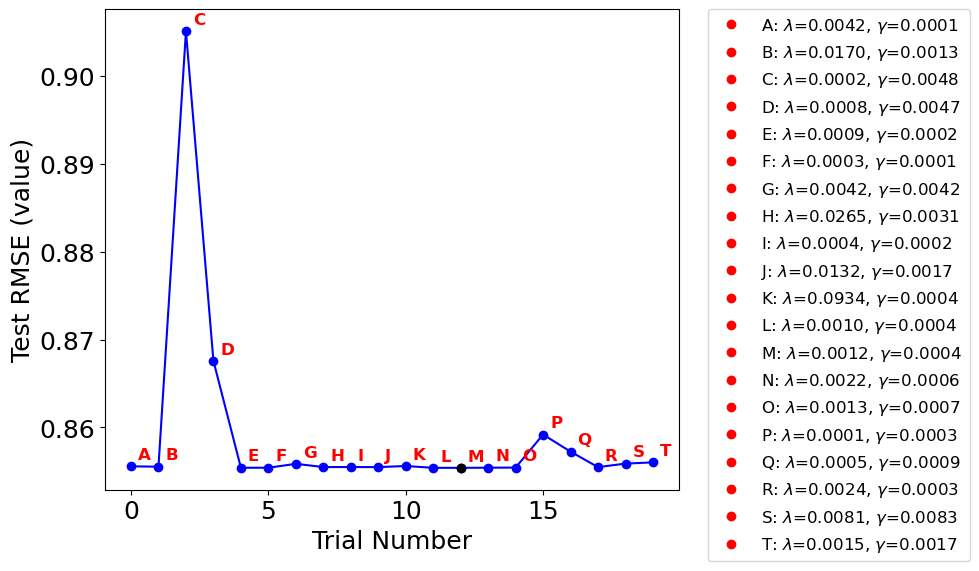

In [7]:
def make_labels(max_letters=2):
    labels = []
    for r in range(1, max_letters + 1):
        for combo in itertools.product(string.ascii_uppercase, repeat=r):
            labels.append("".join(combo))
    return labels

df = study_bias.trials_dataframe().sort_values("number").reset_index(drop=True)

labels_list = make_labels()

plt.figure(figsize=(10, 6))

plt.plot(df["number"], df["value"], marker="o", color="blue", linestyle="-")
plt.plot(best_trial_bias.number, best_trial_bias.value, marker="o", color="black")
plt.xlabel("Trial Number")
plt.ylabel("Test RMSE (value)")

custom_handles = []

for i, row in df.iterrows():
    letter = labels_list[i]
    x_val = row["number"]
    y_val = row["value"]
    
    plt.annotate(
        letter,
        xy=(x_val, y_val),
        xycoords="data",
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=12,
        fontweight="bold",
        color="red",
    )
    
    param_str = (
        f"{letter}: "
        f"$\\lambda$={row['params_LAMBDA']:.4f}, "
        f"$\\gamma$={row['params_GAMMA']:.4f} "
    )
    
    handle = Line2D(
        [0], [0],
        marker='o',
        color='red',
        label=param_str,
        linewidth=0
    )
    custom_handles.append(handle)

plt.legend(
    handles=custom_handles,
    bbox_to_anchor=(1.05, 1),
    loc='upper left',
    borderaxespad=0.,
    fontsize=12
)

plt.tight_layout()
plt.savefig(os.path.join(image_folder, f"parameter_search_{folder}_bias.pdf"), format='pdf', dpi=3000, bbox_inches='tight')
plt.show()

# Bias + Factors Model

In [5]:
def run_experiment(params, 
                   users_train, users_indices_train, 
                   movies_train, movies_indices_train,
                   users_test,  users_indices_test,
                   map_user_to_id, map_movie_to_id, 
                   n_iterations=10, seed=42):
    """
    Trains the model for `n_iterations` epochs with the given parameters 
    and returns the final training and testing RMSE.
    """
    LAMBDA = params['LAMBDA']
    GAMMA  = params['GAMMA']
    TAU    = params['TAU']
    K      = params['K']

    np.random.seed(seed)

    # Initialize biases & embeddings
    n_users, n_movies = len(map_user_to_id), len(map_movie_to_id)
    user_biases = np.zeros(n_users)
    movie_biases = np.zeros(n_movies)
    user_embeddings = np.random.normal(0, 1/np.sqrt(K), size=(n_users, K))
    movie_embeddings = np.random.normal(0, 1/np.sqrt(K), size=(n_movies, K))

    rmse_history = {'train': [], 'test': []}

    with tqdm(range(n_iterations), unit='epochs', leave=False) as tepochs:
        tepochs.set_description('Training')
        for epoch in tepochs:
            # Update user biases and embeddings
            user_biases, user_embeddings = m.update_user_biases_and_embeddings(
                users_train, users_indices_train,
                user_biases, user_embeddings, 
                movie_embeddings, movie_biases, 
                LAMBDA, GAMMA, TAU
            )

            # Update movie biases and embeddings
            movie_biases, movie_embeddings = m.update_movie_biases_and_embeddings(
                movies_train, movies_indices_train,
                user_biases, user_embeddings, 
                movie_embeddings, movie_biases, 
                LAMBDA, GAMMA, TAU
            )

            # Compute RMSE for train and test
            train_rmse = m.compute_rmse_with_embeddings(
                users_train, users_indices_train,
                user_biases, user_embeddings,
                movie_biases, movie_embeddings
            )
            test_rmse = m.compute_rmse_with_embeddings(
                users_test, users_indices_test,
                user_biases, user_embeddings,
                movie_biases, movie_embeddings
            )

            rmse_history['train'].append(train_rmse)
            rmse_history['test'].append(test_rmse)

            tepochs.set_postfix(
                epoch=epoch+1,
                rmse_train=rmse_history['train'][-1],
                rmse_test=rmse_history['test'][-1]
            )

    # Final RMSE after n_iterations
    final_train_rmse = rmse_history['train'][-1]
    final_test_rmse  = rmse_history['test'][-1]
    return final_train_rmse, final_test_rmse

In [7]:
def objective(trial):
    LAMBDA = trial.suggest_float('LAMBDA', 1e-4, 1e-1, log=True)
    GAMMA = trial.suggest_float('GAMMA', 1e-4, 1e-2, log=True)
    TAU = trial.suggest_float('TAU', 0.5, 1.0)
    K = 16 # trial.suggest_categorical('K', [2, 4, 8, 16, 32])
    
    params = {
        'LAMBDA': LAMBDA,
        'GAMMA':  GAMMA,
        'TAU':    TAU,
        'K':      K
    }

    _, final_test_rmse = run_experiment(
        params=params,
        users_train=users_train, users_indices_train=users_indices_train,
        movies_train=movies_train, movies_indices_train=movies_indices_train,
        users_test=users_test, users_indices_test=users_indices_test,
        map_user_to_id=map_user_to_id, map_movie_to_id=map_movie_to_id,
        n_iterations=10,
        seed=42
    )
    return final_test_rmse


logger = setup_logging(logs_path, 'experiment_log_bias_factors.txt')
logger.info("===== Starting Optuna bias+factors parameter tuning =====")

optuna.logging.set_verbosity(optuna.logging.INFO)
optuna.logging.enable_propagation()       # let Optuna logs go to root logger
optuna.logging.disable_default_handler()  # disable Optuna's own handler

logger.info("Starting Optuna study: bias_factors_param_tuning")

study_bias_factors = optuna.create_study(
    study_name='bias_factor_param_tuning',
    direction='minimize'
)

n_trials=20
logger.info(f"Running optimization for {n_trials} trials...")
study_bias_factors.optimize(objective, n_trials=n_trials)

best_trial_bias_factors = study_bias_factors.best_trial

logger.info(f"Best trial parameters: {best_trial_bias_factors.params}")
logger.info(f"Best trial test RMSE: {best_trial_bias_factors.value:.10f}")

save_data_to_pickle(os.path.join(save_path), study_bias_factors, 'params_bias_factors')
logger.info(f"Saved Optuna study to: {os.path.join(save_path, 'params_bias_factors.pkl')}")
logger.info("Optuna tuning finished.")

logger.info("===== Optuna tuning finished successfully =====")

2025-12-03 09:05:24,939 - INFO - ===== Starting Optuna bias+factors parameter tuning =====
2025-12-03 09:05:24,941 - INFO - Starting Optuna study: bias_factors_param_tuning
2025-12-03 09:05:24,943 - INFO - A new study created in memory with name: bias_factor_param_tuning
2025-12-03 09:05:24,950 - INFO - Running optimization for 20 trials...


2025-12-03 09:10:07,851 - INFO - Trial 0 finished with value: 0.8421070562293915 and parameters: {'LAMBDA': 0.0033212114522038214, 'GAMMA': 0.003090852649488846, 'TAU': 0.8799605904908776}. Best is trial 0 with value: 0.8421070562293915.


2025-12-03 09:14:21,639 - INFO - Trial 1 finished with value: 0.8751956807111122 and parameters: {'LAMBDA': 0.0002699017342654269, 'GAMMA': 0.0023543181751926236, 'TAU': 0.7453990670221291}. Best is trial 0 with value: 0.8421070562293915.


2025-12-03 09:18:42,167 - INFO - Trial 2 finished with value: 0.849032169565341 and parameters: {'LAMBDA': 0.0026132196326142314, 'GAMMA': 0.0012831614766328236, 'TAU': 0.8418059215853047}. Best is trial 0 with value: 0.8421070562293915.


2025-12-03 09:23:04,453 - INFO - Trial 3 finished with value: 0.7759253603743741 and parameters: {'LAMBDA': 0.06357156866708429, 'GAMMA': 0.004466388775146481, 'TAU': 0.9186600349145763}. Best is trial 3 with value: 0.7759253603743741.


...

2025-12-03 10:14:30,563 - INFO - Trial 15 finished with value: 0.7752564995005864 and parameters: {'LAMBDA': 0.021434047693422317, 'GAMMA': 0.006020742799914287, 'TAU': 0.6307330425982836}. Best is trial 10 with value: 0.7744194298331346.


2025-12-03 10:18:47,934 - INFO - Trial 16 finished with value: 0.855495623577319 and parameters: {'LAMBDA': 0.0009384921274847854, 'GAMMA': 0.0005902313697737277, 'TAU': 0.6667721345361965}. Best is trial 10 with value: 0.7744194298331346.


2025-12-03 10:23:04,705 - INFO - Trial 17 finished with value: 0.7759319861130621 and parameters: {'LAMBDA': 0.03556524192787023, 'GAMMA': 0.0001436794058804298, 'TAU': 0.5557796847158917}. Best is trial 10 with value: 0.7744194298331346.


2025-12-03 10:27:20,566 - INFO - Trial 18 finished with value: 0.939379336005189 and parameters: {'LAMBDA': 0.000125424419028992, 'GAMMA': 0.00709507330954473, 'TAU': 0.5068122442942274}. Best is trial 10 with value: 0.7744194298331346.


2025-12-03 10:31:36,526 - INFO - Trial 19 finished with value: 0.7925201084785424 and parameters: {'LAMBDA': 0.007523571919268776, 'GAMMA': 0.004287895202631371, 'TAU': 0.6761391584213514}. Best is trial 10 with value: 0.7744194298331346.
2025-12-03 10:31:36,530 - INFO - Best trial parameters: {'LAMBDA': 0.021591275114794476, 'GAMMA': 0.009261374425806558, 'TAU': 0.5092269775538989}
2025-12-03 10:31:36,531 - INFO - Best trial test RMSE: 0.7744194298
Saved params_bias_factors to .pkl file at experiments/ml-32m/model_files
2025-12-03 10:31:36,539 - INFO - Saved Optuna study to: experiments/ml-32m/model_files/params_bias_factors.pkl
2025-12-03 10:31:36,540 - INFO - Optuna tuning finished.
2025-12-03 10:31:36,543 - INFO - ===== Optuna tuning finished successfully =====


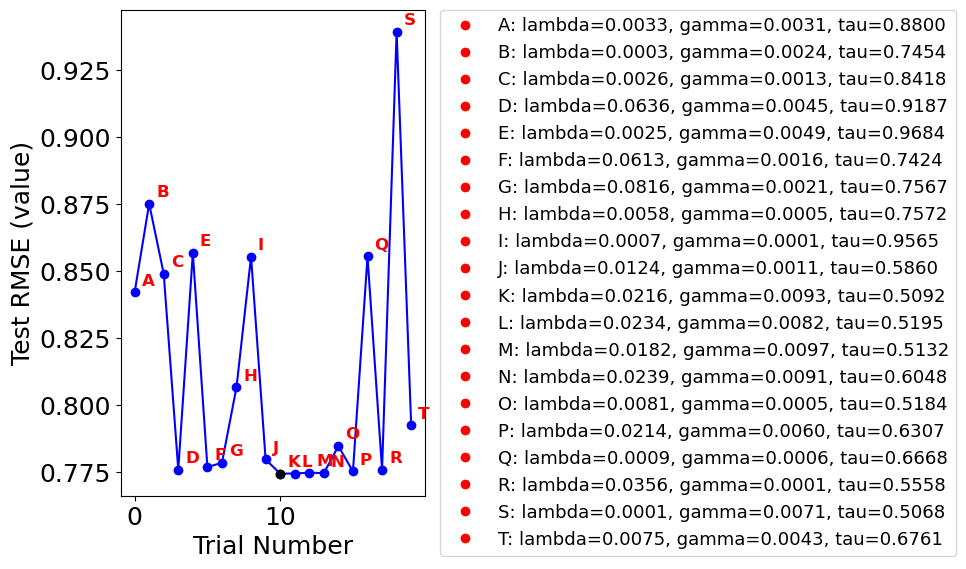

In [ ]:
def make_labels(max_letters=2):
    labels = []
    for r in range(1, max_letters + 1):
        for combo in itertools.product(string.ascii_uppercase, repeat=r):
            labels.append("".join(combo))
    return labels

df = study_bias_factors.trials_dataframe().sort_values("number").reset_index(drop=True)

labels_list = make_labels()

plt.figure(figsize=(10, 6))

plt.plot(df["number"], df["value"], marker="o", color="blue", linestyle="-")
plt.plot(best_trial_bias_factors.number, best_trial_bias_factors.value, marker="o", color="black")
plt.xlabel("Trial Number")
plt.ylabel("Test RMSE (value)")
#plt.title("Optuna Trials: Test RMSE vs. Trial Number")

custom_handles = []

for i, row in df.iterrows():
    letter = labels_list[i]
    x_val = row["number"]
    y_val = row["value"]
    
    plt.annotate(
        letter,
        xy=(x_val, y_val),
        xycoords="data",
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=12,
        fontweight="bold",
        color="red",
    )
    
    param_str = (
        f"{letter}: "
        f"$\\lambda$={row['params_LAMBDA']:.4f}, "
        f"$\\gamma$={row['params_GAMMA']:.4f}, "
        f"$\\tau$={row['params_TAU']:.4f}"
    )
    
    handle = Line2D(
        [0], [0],
        marker='o',
        color='red',
        label=param_str,
        linewidth=0
    )
    custom_handles.append(handle)

plt.legend(
    handles=custom_handles,
    bbox_to_anchor=(1.05, 1),
    loc='upper left',
    borderaxespad=0.,
    fontsize=13
)

plt.tight_layout()
plt.savefig(os.path.join(image_folder, f"parameter_search_{folder}_k_16.pdf"), format='pdf', dpi=3000, bbox_inches='tight')
plt.show()